In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense
from sklearn.preprocessing import MinMaxScaler
from keras.callbacks import ModelCheckpoint,EarlyStopping,TensorBoard


In [3]:
data = pd.read_csv("synthetic_traffic_data.csv")
data

,timestamp,location_id,day_of_week,hour_of_day,traffic_flow
0,2023-01-01 00:00:00,7,6,0,12
1,2023-01-01 00:15:00,4,6,0,17
2,2023-01-01 00:30:00,8,6,0,38
3,2023-01-01 00:45:00,5,6,0,20
4,2023-01-01 01:00:00,7,6,1,21
...,...,...,...,...,...
1435,2023-01-15 22:45:00,9,6,22,38
1436,2023-01-15 23:00:00,8,6,23,30
1437,2023-01-15 23:15:00,9,6,23,20
1438,2023-01-15 23:30:00,5,6,23,6


In [6]:
data["hour"] = pd.to_datetime(data['timestamp']).dt.hour
data["day"] = pd.to_datetime(data['timestamp']).dt.day_of_week
data['year'] = pd.to_datetime(data['timestamp']).dt.year

In [7]:
print(data)

                timestamp  location_id  day_of_week  hour_of_day  \
0     2023-01-01 00:00:00            7            6            0   
1     2023-01-01 00:15:00            4            6            0   
2     2023-01-01 00:30:00            8            6            0   
3     2023-01-01 00:45:00            5            6            0   
4     2023-01-01 01:00:00            7            6            1   
...                   ...          ...          ...          ...   
1435  2023-01-15 22:45:00            9            6           22   
1436  2023-01-15 23:00:00            8            6           23   
1437  2023-01-15 23:15:00            9            6           23   
1438  2023-01-15 23:30:00            5            6           23   
1439  2023-01-15 23:45:00            2            6           23   

      traffic_flow  hour  day  year  
0               12     0    6  2023  
1               17     0    6  2023  
2               38     0    6  2023  
3               20     0    6  

In [9]:
scaler = MinMaxScaler()
data['traffic_flow_scaled'] = scaler.fit_transform(data[['traffic_flow']])

In [10]:
data

,timestamp,location_id,day_of_week,hour_of_day,traffic_flow,hour,day,year,traffic_flow_scaled
0,2023-01-01 00:00:00,7,6,0,12,0,6,2023,0.086957
1,2023-01-01 00:15:00,4,6,0,17,0,6,2023,0.111111
2,2023-01-01 00:30:00,8,6,0,38,0,6,2023,0.212560
3,2023-01-01 00:45:00,5,6,0,20,0,6,2023,0.125604
4,2023-01-01 01:00:00,7,6,1,21,1,6,2023,0.130435
...,...,...,...,...,...,...,...,...,...
1435,2023-01-15 22:45:00,9,6,22,38,22,6,2023,0.212560
1436,2023-01-15 23:00:00,8,6,23,30,23,6,2023,0.173913
1437,2023-01-15 23:15:00,9,6,23,20,23,6,2023,0.125604
1438,2023-01-15 23:30:00,5,6,23,6,23,6,2023,0.057971


In [18]:
X = data.iloc[:,2:4].values
y = data['traffic_flow_scaled'].values

In [19]:
X

array([[ 6,  0],
       [ 6,  0],
       [ 6,  0],
       ...,
       [ 6, 23],
       [ 6, 23],
       [ 6, 23]], dtype=int64)

In [21]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [22]:
model = Sequential()
model.add(Dense(units=64,activation='relu',input_dim=2))
model.add(Dense(units=32,activation='relu'))
model.add(Dense(units=1))

In [23]:
model.compile(optimizer='rmsprop',metrics=['mse'],loss='mae')
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                192       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2,305
Trainable params: 2,305
Non-trainable params: 0
_________________________________________________________________


In [26]:
model_checkpoint = ModelCheckpoint(filepath="model.h5",monitor='val_loss',verbose=1)
early_stop = EarlyStopping(monitor='val_loss',patience=3,verbose=1)
tb = TensorBoard('logs',histogram_freq=1,embeddings_freq=1,write_graph=True)


In [29]:
history = model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=15,callbacks=[model_checkpoint,early_stop,tb])


Epoch 1/15
 1/36 [..............................] - ETA: 0s - loss: 0.3176 - mse: 0.1286
Epoch 1: saving model to model.h5
36/36 [==============================] - 0s 4ms/step - loss: 0.2083 - mse: 0.0700 - val_loss: 0.1551 - val_mse: 0.0403
Epoch 2/15
 1/36 [..............................] - ETA: 0s - loss: 0.1638 - mse: 0.0471
Epoch 2: saving model to model.h5
36/36 [==============================] - 0s 4ms/step - loss: 0.2115 - mse: 0.0715 - val_loss: 0.1564 - val_mse: 0.0418
Epoch 3/15
 1/36 [..............................] - ETA: 0s - loss: 0.1249 - mse: 0.0311
Epoch 3: saving model to model.h5
36/36 [==============================] - 0s 3ms/step - loss: 0.2010 - mse: 0.0659 - val_loss: 0.1651 - val_mse: 0.0522
Epoch 4/15
 1/36 [..............................] - ETA: 0s - loss: 0.1600 - mse: 0.0516
Epoch 4: saving model to model.h5
36/36 [==============================] - 0s 3ms/step - loss: 0.1960 - mse: 0.0639 - val_loss: 0.1941 - val_mse: 0.0521
Epoch 4: early stopping


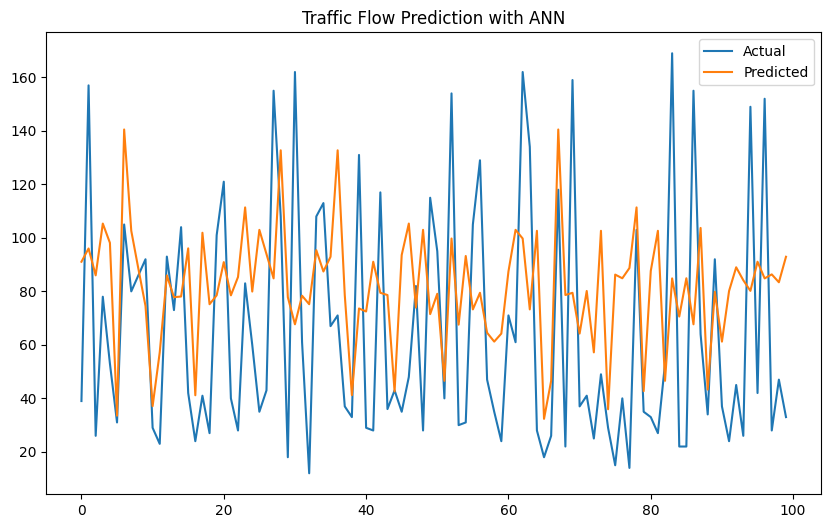

In [ ]:
predictions = model.predict(X_test)
predictions_rescaled = scaler.inverse_transform(predictions)
y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1, 1))


plt.figure(figsize=(10, 6))
plt.plot(y_test_rescaled[:100], label='Actual')
plt.plot(predictions_rescaled[:100], label='Predicted')
plt.title('Traffic Flow Prediction with ANN')
plt.legend()
plt.show()